# 1. Imports and settings
Imports, `random_state=42`, and paths from `config.py`.

In [1]:
import sys, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings("ignore")

sys.path.append(str(Path.cwd().parent))
import config

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             precision_recall_fscore_support, classification_report, confusion_matrix,
                             roc_curve, auc, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = config.RANDOM_STATE
MODEL_NAME = "random_forest"
MODEL_DIR = config.MODELS_DIR / MODEL_NAME
MODEL_DIR.mkdir(parents=True, exist_ok=True)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"{MODEL_NAME}: random_state={RANDOM_STATE}")

random_forest: random_state=42


# 2. Load the 70/30 split
Load `train.csv` / `test.csv`; print shapes and class counts. `athlete_id` is kept only to group the CV folds.

In [2]:
train_df = pd.read_csv(config.PROCESSED_DATA_DIR / "train.csv")
test_df = pd.read_csv(config.PROCESSED_DATA_DIR / "test.csv")
n = len(train_df) + len(test_df)
print(f"Total rows {n} | train {len(train_df)} ({len(train_df)/n:.1%}) | test {len(test_df)} ({len(test_df)/n:.1%})")
for nm, part in (("Train", train_df), ("Test", test_df)):
    vc = part[config.CLASS_COLUMN].value_counts().sort_index()
    print(nm, {config.CLASS_NAMES[k]: f"{v} ({v/len(part):.1%})" for k, v in vc.items()})

Total rows 15420 | train 10775 (69.9%) | test 4645 (30.1%)
Train {'Low': '3621 (33.6%)', 'Moderate': '3613 (33.5%)', 'High': '3541 (32.9%)'}
Test {'Low': '1565 (33.7%)', 'Moderate': '1551 (33.4%)', 'High': '1529 (32.9%)'}


# 3. Assert features, leakage safety and the shared split
Exactly the 7 inputs, no target/id column in X, and the same rows as `split_indices.json`.

In [3]:
FEATURE_COLS = list(config.FEATURE_COLUMNS)
assert len(FEATURE_COLS) == 7, FEATURE_COLS
forbidden = {config.TARGET_COLUMN, config.CLASS_COLUMN, "athlete_id", "session_id"}
assert not forbidden & set(FEATURE_COLS), "target/id column found in features!"

split = json.loads((config.PROCESSED_DATA_DIR / "split_indices.json").read_text())
full = pd.read_csv(config.PROCESSED_DATA_DIR / "fatigue_7features.csv")
assert np.array_equal(full.iloc[split["train_indices"]][config.TARGET_COLUMN].values, train_df[config.TARGET_COLUMN].values)
assert np.array_equal(full.iloc[split["test_indices"]][config.TARGET_COLUMN].values, test_df[config.TARGET_COLUMN].values)
assert not set(train_df["athlete_id"]) & set(test_df["athlete_id"]), "athlete appears in both sets"

X_train, y_train = train_df[FEATURE_COLS], train_df[config.CLASS_COLUMN]
X_test, y_test = test_df[FEATURE_COLS], test_df[config.CLASS_COLUMN]
GROUPS = train_df["athlete_id"]
print("Features (in order):", FEATURE_COLS)
print("Split matches split_indices.json; no athlete in both train and test.")

Features (in order): ['training_duration', 'training_intensity', 'training_load', 'heart_rate', 'sleep_quality', 'recovery_score', 'stress_level']
Split matches split_indices.json; no athlete in both train and test.


# 4. Preprocessing + model pipeline
Median imputer (fit on train folds only) -> Random Forest.

In [4]:
est = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # fitted on training folds only
    ("classifier", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
print(est)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])


# 5. Hyperparameter search (5-fold stratified, athlete-grouped CV on train only)
Scoring macro-F1; accuracy is recorded too. Saves `best_params.json`.

In [5]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [6, 8, 12, None],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2, 4],
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
t0 = time.perf_counter()
grid_search = GridSearchCV(est, param_grid, cv=cv, scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
                           refit="f1_macro", n_jobs=-1)
grid_search.fit(X_train, y_train, groups=GROUPS)
search_time = time.perf_counter() - t0

best_cv_f1 = float(grid_search.best_score_)
best_cv_acc = float(grid_search.cv_results_["mean_test_accuracy"][grid_search.best_index_])
best_params = {k.replace("classifier__", ""): v for k, v in grid_search.best_params_.items()}
print(f"Best CV macro-F1 : {best_cv_f1:.4f}")
print(f"CV accuracy      : {best_cv_acc:.4f}")
print(f"Best parameters  : {best_params}")
print(f"Search wall time : {search_time:.1f}s")
with open(MODEL_DIR / "best_params.json", "w") as f:
    json.dump(best_params, f, indent=2, default=str)
print("Saved best_params.json")

Best CV macro-F1 : 0.6698
CV accuracy      : 0.6689
Best parameters  : {'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Search wall time : 82.6s
Saved best_params.json


# 6. Fit final model on the full training set
Timed with `time.perf_counter()` (wall time).

In [6]:
final_model = grid_search.best_estimator_
t0 = time.perf_counter()
final_model.fit(X_train, y_train)
fit_time = time.perf_counter() - t0
total_training_time = search_time + fit_time
print(f"Final fit (fit only): {fit_time:.4f}s | search + fit: {total_training_time:.1f}s")

Final fit (fit only): 0.9217s | search + fit: 83.5s


# 7. Training accuracy vs CV accuracy (overfitting check)
A large positive gap means variance; both low means weak signal.

In [7]:
train_acc = float(accuracy_score(y_train, final_model.predict(X_train)))
cv_acc = best_cv_acc
gap = train_acc - cv_acc
print(f"Train accuracy: {train_acc:.4f}")
print(f"CV accuracy   : {cv_acc:.4f}")
print(f"Gap (train - CV): {gap:+.4f}")

Train accuracy: 0.8706
CV accuracy   : 0.6689
Gap (train - CV): +0.2017


# 8. FINAL TEST EVALUATION (the only cell that scores the model on test.csv)
Accuracy, macro P/R/F1, weighted F1, ROC-AUC (OvR), per-class P/R/F1. Saves `metrics.csv`.

In [8]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)

test_acc = float(accuracy_score(y_test, y_pred))
p_mac = float(precision_score(y_test, y_pred, average="macro"))
r_mac = float(recall_score(y_test, y_pred, average="macro"))
f1_mac = float(f1_score(y_test, y_pred, average="macro"))
f1_w = float(f1_score(y_test, y_pred, average="weighted"))
auc_ovr = float(roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"))
p_c, r_c, f_c, _ = precision_recall_fscore_support(y_test, y_pred)

print(f"Accuracy {test_acc:.4f} | macro P {p_mac:.4f} R {r_mac:.4f} F1 {f1_mac:.4f} | weighted F1 {f1_w:.4f} | ROC-AUC {auc_ovr:.4f}")
print(classification_report(y_test, y_pred, target_names=config.CLASS_NAMES, digits=4))
if test_acc > 0.95 or test_acc - cv_acc > 0.03:
    print("WARNING: suspicion rule triggered (test > 0.95 or test exceeds CV by > 3 points). Re-check for leakage.")

row = {"model_name": MODEL_NAME, "accuracy": test_acc, "test_accuracy": test_acc,
       "precision_macro": p_mac, "recall_macro": r_mac, "f1_macro": f1_mac, "macro_f1": f1_mac,
       "f1_weighted": f1_w, "weighted_f1": f1_w, "roc_auc_ovr": auc_ovr, "roc_auc_macro_ovr": auc_ovr,
       "cv_macro_f1": best_cv_f1, "cv_accuracy": cv_acc, "train_accuracy": train_acc,
       "overfit_gap": gap, "meets_target": bool(test_acc >= 0.80), "in_range_80_85": bool(0.80 <= test_acc <= 0.85)}
for i, cn in enumerate(config.CLASS_NAMES):
    row[f"precision_{cn}"], row[f"recall_{cn}"], row[f"f1_{cn}"] = float(p_c[i]), float(r_c[i]), float(f_c[i])
pd.DataFrame([row]).to_csv(MODEL_DIR / "metrics.csv", index=False)
print("Saved metrics.csv")

Accuracy 0.6633 | macro P 0.6655 R 0.6633 F1 0.6641 | weighted F1 0.6639 | ROC-AUC 0.8431
              precision    recall  f1-score   support

         Low     0.7177    0.7457    0.7314      1565
    Moderate     0.5234    0.5332    0.5283      1551
        High     0.7554    0.7109    0.7325      1529

    accuracy                         0.6633      4645
   macro avg     0.6655    0.6633    0.6641      4645
weighted avg     0.6652    0.6633    0.6639      4645

Saved metrics.csv


# 9. Confusion matrix and ROC curves
Saved to `reports/figures/`.

Saved C:\Users\Resona\Downloads\fatigue_prediction\reports\figures\random_forest_evaluation.png


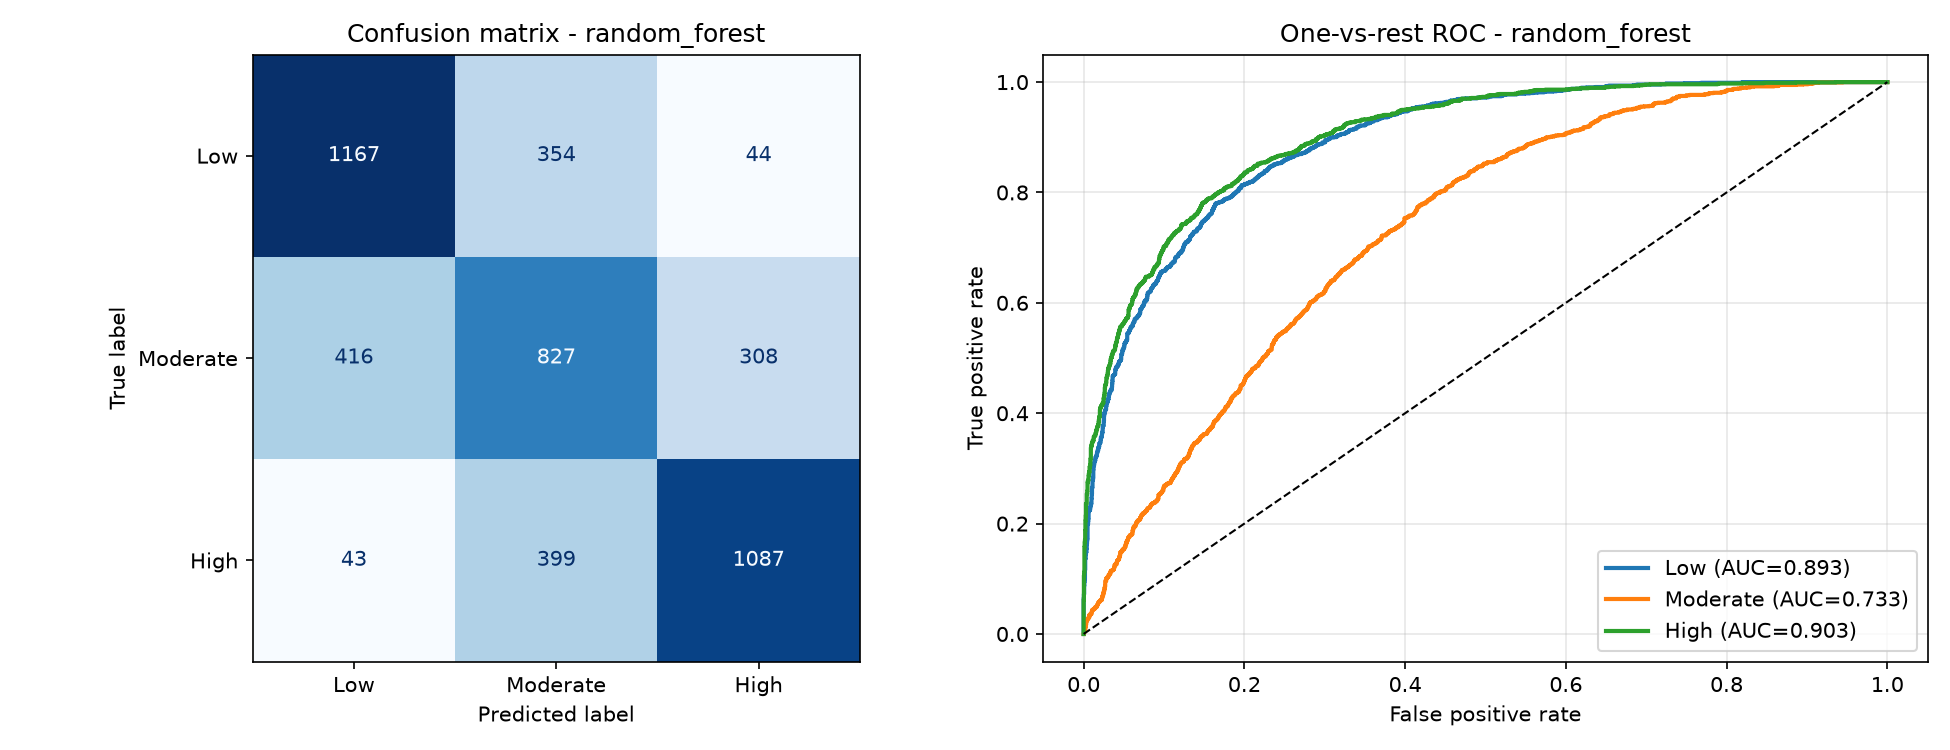

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=config.CLASS_NAMES).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix - {MODEL_NAME}")
for i, cn in enumerate(config.CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test == i, y_proba[:, i])
    axes[1].plot(fpr, tpr, lw=2, label=f"{cn} (AUC={auc(fpr, tpr):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set(title=f"One-vs-rest ROC - {MODEL_NAME}", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(loc="lower right"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / f"{MODEL_NAME}_evaluation.png", dpi=150)
plt.show(); plt.close()
print("Saved", config.FIGURES_DIR / f"{MODEL_NAME}_evaluation.png")

# 10. Permutation importance (10 repeats)
Macro-F1 drop when each feature is shuffled; saved as CSV and bar plot.

           feature  importance_mean  importance_std
     training_load         0.307873        0.005271
    recovery_score         0.021241        0.003009
 training_duration         0.005497        0.004931
      stress_level         0.003908        0.002247
training_intensity         0.003306        0.002898
        heart_rate         0.002207        0.001545
     sleep_quality        -0.000340        0.002526


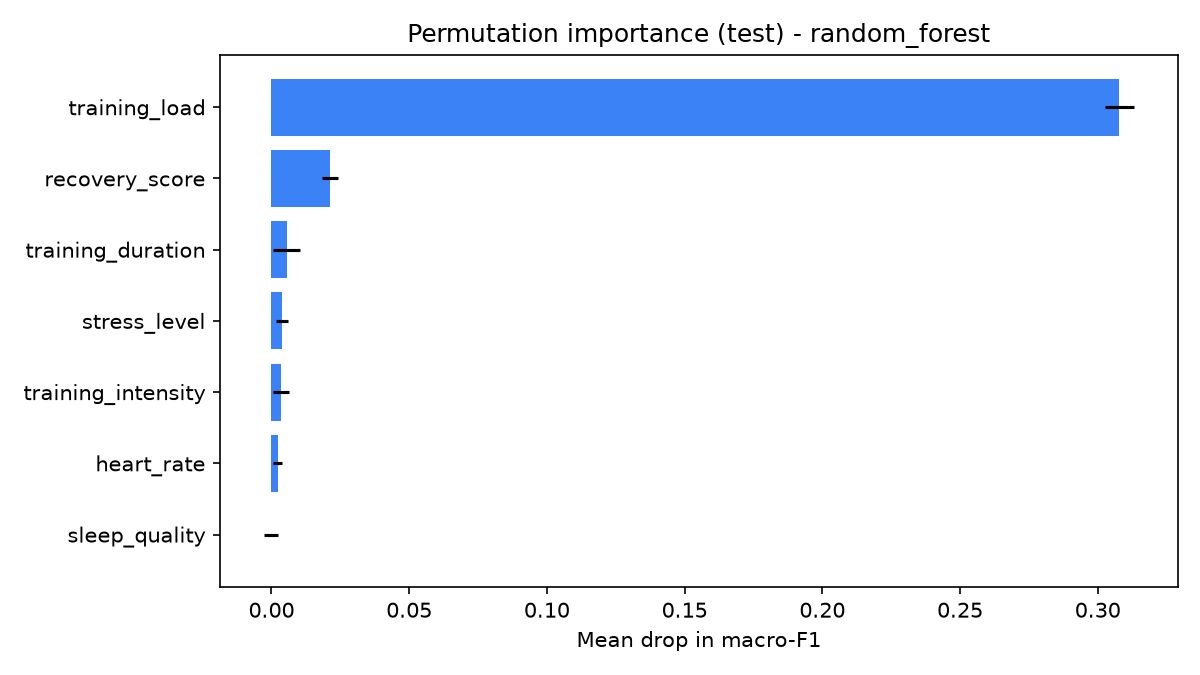

In [10]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                              scoring="f1_macro", n_jobs=-1)
perm_df = pd.DataFrame({"feature": FEATURE_COLS, "importance_mean": perm.importances_mean,
                        "importance_std": perm.importances_std}).sort_values("importance_mean", ascending=False)
perm_df.to_csv(MODEL_DIR / "permutation_importance.csv", index=False)
print(perm_df.to_string(index=False))
plt.figure(figsize=(8, 4.5))
d = perm_df.iloc[::-1]
plt.barh(d["feature"], d["importance_mean"], xerr=d["importance_std"], color="#3b82f6")
plt.title(f"Permutation importance (test) - {MODEL_NAME}"); plt.xlabel("Mean drop in macro-F1")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / f"{MODEL_NAME}_permutation_importance.png", dpi=150)
plt.show(); plt.close()

# 11. Prediction time per 1,000 rows
Measured on 1,000 training rows (no test data needed); saves `wall_time.csv`.

In [11]:
bench = X_train.sample(n=1000, random_state=RANDOM_STATE)
final_model.predict(bench)  # warm-up
t0 = time.perf_counter()
for _ in range(10):
    final_model.predict(bench)
pred_ms = (time.perf_counter() - t0) / 10 * 1000
pd.DataFrame([{"model_name": MODEL_NAME, "search_wall_time_seconds": search_time,
               "fit_wall_time_seconds": fit_time, "total_training_wall_time_s": total_training_time,
               "prediction_time_per_1k_ms": pred_ms}]).to_csv(MODEL_DIR / "wall_time.csv", index=False)
print(f"Search {search_time:.1f}s | fit only {fit_time:.4f}s | total {total_training_time:.1f}s | predict/1k rows {pred_ms:.2f} ms")

Search 82.6s | fit only 0.9217s | total 83.5s | predict/1k rows 77.88 ms


# 12. Save model and `model_config.json`
Feature list and order, class names, library versions.

In [12]:
import platform
import sklearn; LIB = {'sklearn': sklearn.__version__}
joblib.dump(final_model, MODEL_DIR / "model.joblib")

model_config = {"model_name": MODEL_NAME, "algorithm": "RandomForestClassifier", "feature_names": FEATURE_COLS,
                "class_names": config.CLASS_NAMES, "random_state": RANDOM_STATE,
                "split": "70/30 athlete-grouped stratified", "python": platform.python_version(),
                "pandas": pd.__version__, "numpy": np.__version__, **LIB, "best_hyperparameters": best_params}
with open(MODEL_DIR / "model_config.json", "w") as f:
    json.dump(model_config, f, indent=2, default=str)
print("Saved model.joblib and model_config.json to", MODEL_DIR)

Saved model.joblib and model_config.json to C:\Users\Resona\Downloads\fatigue_prediction\models\random_forest


# 13. Summary
Real numbers, printed whether or not they fall in 0.80-0.85.

In [13]:
in_range = 0.80 <= test_acc <= 0.85
print(f"[{MODEL_NAME}] accuracy={test_acc:.4f} | macro-F1={f1_mac:.4f} | ROC-AUC={auc_ovr:.4f} | "
      f"training time={total_training_time:.1f}s | within 0.80-0.85: {in_range}")

[random_forest] accuracy=0.6633 | macro-F1=0.6641 | ROC-AUC=0.8431 | training time=83.5s | within 0.80-0.85: False
